<a href="https://colab.research.google.com/github/frandresst-wq/Proyecto-de-Ciencia-de-Datos/blob/main/S3_Cuaderno_Entrega_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 3 — Análisis exploratorio de tu conjunto de datos
**Ciencia de Datos · Semana 3 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA2 (parte 1) · RA3 (transversal) |
| **Duración estimada** | 1,5 h asincrónicas + 1 h de trabajo autónomo |
| **Insumo** | `mi_conjunto_limpio.csv`, producido en la semana 2 |
| **Producto** | Este cuaderno completo — **es la Entrega 2** |
| **Estudiante** | _(Franco Soto Soto)_ |

---



**Este cuaderno es la entrega.** No hay informe aparte. Lo que se evalúa es que cada resultado venga acompañado de su lectura: *un resultado sin interpretación no es un hallazgo, es un número suelto*.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = ''
SEMILLA = 20263
np.random.seed(SEMILLA)
plt.rcParams['figure.figsize'] = (9, 4)

df = pd.read_csv(RUTA + 'mi_conjunto_limpio.csv', sep=';')
print('Forma:', df.shape)
df.head()

Forma: (720, 12)


,id_registro,estacion_id,estacion,comuna,region,fecha,pm25,pm10,temperatura_c,humedad_pct,validado,mes
0,02-20260626,2,LOS ANGELES ORIENTE,LOS ANGELES,BIOBIO,2026-06-26,77.1,154.9,9.5,58.3,SI,6
1,08-20260405,8,CORONEL NORTE,CORONEL,BIOBIO,2026-04-05,31.6,52.0,12.7,65.4,SI,4
2,06-20260621,6,OSORNO ENTRE LAGOS,OSORNO,LOS LAGOS,2026-06-21,63.5,111.4,6.7,83.0,SI,6
3,01-20260531,1,KINGSTON,CONCEPCION,BIOBIO,2026-05-31,48.1,79.4,14.4,75.1,SI,5
4,05-20260522,5,TEMUCO PADRE LAS CASAS,TEMUCO,ARAUCANIA,2026-05-22,85.0,162.1,11.5,82.9,SI,5


### Punto de partida

Antes de explorar, recuerda a dónde vas. Copia aquí lo que escribiste en la Entrega 1:

- **Mi pregunta analítica es:**_¿Cómo varían las concentraciones de material particulado PM2.5 entre las distintas estaciones de monitoreo y a lo largo del tiempo?_
- **Una fila de mi conjunto representa:** _Un registro de medición de calidad del aire asociado a una estación de monitoreo y una fecha determinada, con valores de PM2.5, PM10, temperatura y humedad._

Todo lo que sigue debe servir para responder esa pregunta. Si un gráfico no aporta a ella, sobra.

---
## Parte 1 · Análisis univariado

Una variable a la vez. El objetivo es conocer la forma de cada una antes de relacionarlas.\
+++++ El análisis univariado consiste en estudiar una variable a la vez, sin relacionarla todavía con otras variables del conjunto de datos.

Su objetivo es conocer cómo se distribuyen los valores, identificar valores extremos, detectar posibles anomalías y comprender el comportamiento general de cada variable.

In [ ]:
# Resumen numérico de todas las variables cuantitativas
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
estacion_id,720.0,4.50,2.29,1.0,2.75,4.50,6.25,8.0
pm25,686.0,62.26,51.21,12.9,46.32,57.30,67.18,586.7
pm10,702.0,104.43,29.93,22.7,84.20,105.20,122.48,201.4
temperatura_c,720.0,11.03,3.21,0.1,8.90,11.00,13.20,20.6
humedad_pct,720.0,75.89,8.66,50.7,70.28,75.75,81.82,99.0
mes,720.0,4.99,0.81,4.0,4.00,5.00,6.00,6.0


1. Análisis de cada variable\
estacion_id:	Existen 8 estaciones identificadas con códigos del 1 al 8. Su promedio de 4,50 no tiene significado estadístico, porque es un identificador.\
pm25:	Promedio de 62,26 µg/m³ y desviación estándar de 51,21. Presenta una dispersión considerable y un valor máximo muy elevado (586,70).\
pm10:	Promedio de 104,43 µg/m³. Su mediana es 105,20, muy cercana al promedio, lo que sugiere una distribución relativamente equilibrada alrededor del centro.\
temperatura_c:	Temperatura promedio de 11,03 °C, con valores entre 0,1 y 20,6 °C.\
humedad_pct:	Humedad promedio de 75,89%, con valores entre 50,7% y 99%.\
mes:	Los registros corresponden a los meses 4, 5 y 6. El promedio de 4,99 no es especialmente útil para describir la distribución temporal.

2. Hallazgos importantes\
A. PM2.5 presenta posibles valores atípicos\
B. Existen datos faltantes en PM2.5. Existen 34 valores faltantes, equivalentes al 4,72%.\
C. No todas las variables numéricas son cuantitativas\
estacion_id es un identificador y mes representa una categoría temporal. Aunque aparecen en describe(), no corresponde interpretar sus promedios como si fueran mediciones continuas.\

Conclusión\
El análisis univariado permite identificar que PM2.5 es una variable que requiere especial atención, debido a su elevada dispersión, presencia de posibles valores extremos y registros faltantes.



### ✏️ Actividad 1.1 — Distribuciones

Grafica el histograma de **al menos tres variables numéricas** relevantes para tu pregunta. Para cada una, responde en la celda de texto siguiente:

- ¿Es simétrica o asimétrica? ¿Hacia qué lado?
- ¿Tiene una joroba o más de una? Si tiene más de una, **busca la categoría que la explica** (Ejercicio 1 del cuaderno resuelto).
- ¿Ves picos regulares o valores que se repiten sospechosamente? (Ejercicio 3).

+++++++\
Para esta actividad utilizaremos las siguientes tres variables numéricas:
- pm25: concentración de material particulado fino.
- pm10: concentración de material particulado grueso.
- temperatura_c: temperatura ambiental.\
Estas variables permiten estudiar el comportamiento de la calidad del aire y las condiciones ambientales.

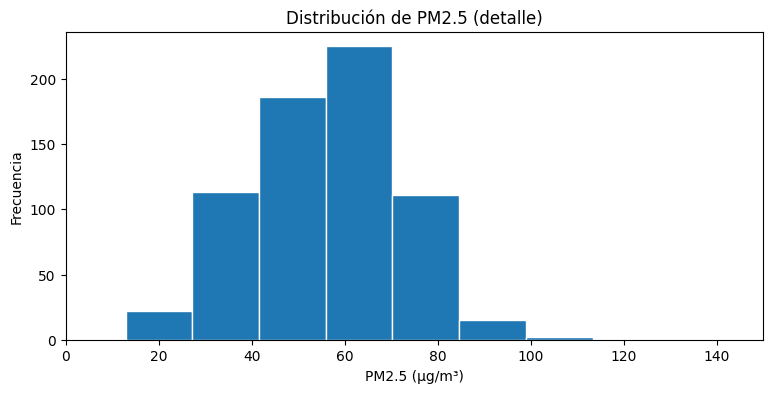

In [ ]:
# Tu código aquí
plt.figure(figsize=(9, 4))
plt.hist(df['pm25'].dropna(), bins=40, edgecolor='white')
#dropna excluye faltantes, bins son los intervalos
plt.xlim(0, 150)
plt.title('Distribución de PM2.5 (detalle)')
plt.xlabel('PM2.5 (µg/m³)')
plt.ylabel('Frecuencia')
plt.show()

La distribución es aproximadamente simétrica, con una sola joroba entre 55 y 70 µg/m³. La mayoría de los valores se concentra entre 30 y 85 µg/m³ y no se observan picos sospechosos en ese rango. Sin embargo, al considerar todos los registros, la distribución es asimétrica hacia la derecha debido a la presencia de valores extremos que alcanzan 586,7 µg/m³.

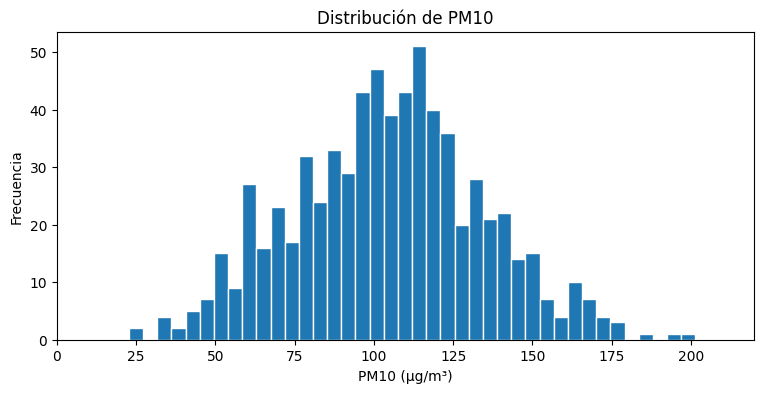

In [ ]:
plt.figure(figsize=(9, 4))
plt.hist(df['pm10'].dropna(), bins=40, edgecolor='white')
plt.xlim(0, 220)
plt.title('Distribución de PM10')
plt.xlabel('PM10 (µg/m³)')
plt.ylabel('Frecuencia')
plt.show()

La distribución es aproximadamente simétrica, con una sola joroba principal alrededor de 100 a 115 µg/m³. La mayoría de las mediciones se concentra entre 75 y 135 µg/m³. No se observan picos sospechosos ni acumulaciones anormales evidentes, aunque existen algunos valores extremos cercanos a 200 µg/m³ que podrían revisarse.

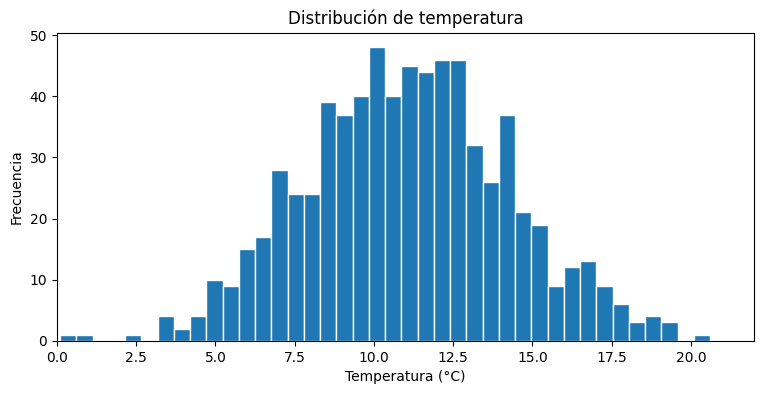

In [ ]:
plt.figure(figsize=(9, 4))
plt.hist(df['temperatura_c'].dropna(), bins=40, edgecolor='white')
plt.xlim(0, 22)
plt.title('Distribución de temperatura')
plt.xlabel('Temperatura (°C)')
plt.ylabel('Frecuencia')
plt.show()

Presenta una distribución aproximadamente simétrica, con una sola joroba principal entre 10 y 13 °C. La mayoría de las mediciones se concentra entre 7 y 15 °C. Su forma se asemeja a una campana y no se observan picos sospechosos ni acumulaciones anormales de valores. Existen algunas temperaturas extremas, pero son poco frecuentes.

### ✏️ Actividad 1.2 — Media contra mediana

Para tu variable numérica principal, compara media, mediana y sesgo. Decide cuál de las dos reportarías en un informe y justifícalo.

In [ ]:
# Tu código aquí
media = df['pm25'].mean()
mediana = df['pm25'].median()
sesgo = df['pm25'].skew()

print('Media:', round(media, 2))
print('Mediana:', round(mediana, 2))
print('Sesgo:', round(sesgo, 2))

Media: 62.26
Mediana: 57.3
Sesgo: 7.22


_Justificación:_\
Los resultados confirman que la distribución de PM2.5 presenta una asimetría positiva muy pronunciada.

| Medida | Valor | Interpretación |
|---|---:|---|
| Media | 62.26 | Promedio de PM2.5 |
| Mediana | 57.30 | El 50% de las mediciones es menor o igual a 57,30 |
| Sesgo | 7.22 | Asimetría positiva muy pronunciada |

Como referencia orientativa:
- Sesgo = 0: distribución simétrica.
- Sesgo positivo: cola hacia la derecha.
- Sesgo negativo: cola hacia la izquierda.

### ✏️ Actividad 1.3 — Variables categóricas

Muestra la frecuencia de tus variables categóricas. Fíjate en dos cosas: categorías con muy pocos casos (¿conviene agruparlas?) y categorías que dominan el conjunto (¿sesgan la conclusión?).

+++++\
El objetivo es analizar cuántos registros pertenecen a cada categoría y determinar si algunas categorías tienen una representación mucho mayor que otras.

En este conjunto de datos de calidad del aire, podemos analizar variables como estacion_id y mes, que, aunque están almacenadas como números, representan categorías.

In [ ]:
for col in df.select_dtypes(include='object').columns:
    print(df[col].value_counts(normalize=True).head(10).round(3), '\n')

id_registro
02-20260410    0.001
03-20260513    0.001
08-20260419    0.001
08-20260401    0.001
05-20260617    0.001
04-20260530    0.001
02-20260517    0.001
02-20260519    0.001
01-20260621    0.001
01-20260601    0.001
Name: proportion, dtype: float64 

estacion
LOS ANGELES ORIENTE       0.125
CORONEL NORTE             0.125
OSORNO ENTRE LAGOS        0.125
KINGSTON                  0.125
TEMUCO PADRE LAS CASAS    0.125
TALCAHUANO                0.125
COYHANCO                  0.125
VALDIVIA CENTRO           0.125
Name: proportion, dtype: float64 

comuna
LOS ANGELES    0.125
CORONEL        0.125
OSORNO         0.125
CONCEPCION     0.125
TEMUCO         0.125
TALCAHUANO     0.125
CHILLAN        0.125
VALDIVIA       0.125
Name: proportion, dtype: float64 

region
BIOBIO       0.500
LOS LAGOS    0.125
ARAUCANIA    0.125
NUBLE        0.125
LOS RIOS     0.125
Name: proportion, dtype: float64 

fecha
2026-06-26    0.011
2026-04-05    0.011
2026-06-21    0.011
2026-05-31    0.011
2026-05-22

In [ ]:
#Para analizar las estaciones:
print(df['estacion_id'].value_counts().sort_index())

estacion_id
1    90
2    90
3    90
4    90
5    90
6    90
7    90
8    90
Name: count, dtype: int64


In [ ]:
#Para analizar los meses:
print(df['mes'].value_counts().sort_index())

mes
4    240
5    248
6    232
Name: count, dtype: int64


In [ ]:
#Para obtener los procentajes
print((df['estacion_id'].value_counts(normalize=True) * 100).round(2))
print((df['mes'].value_counts(normalize=True) * 100).round(2))

estacion_id
2    12.5
8    12.5
6    12.5
1    12.5
5    12.5
4    12.5
3    12.5
7    12.5
Name: proportion, dtype: float64
mes
5    34.44
4    33.33
6    32.22
Name: proportion, dtype: float64


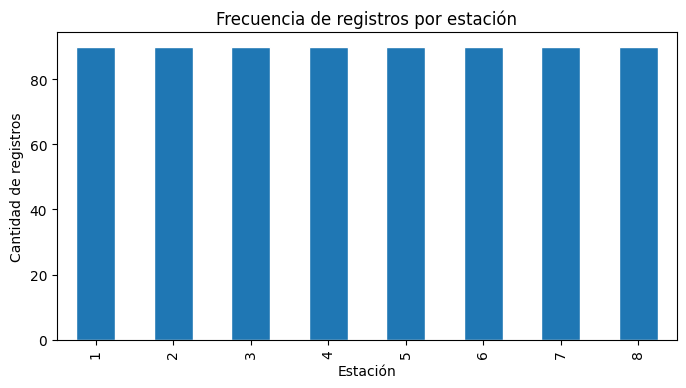

In [ ]:
#Gráfico de barra para detectar frecuencias
import matplotlib.pyplot as plt

df['estacion_id'].value_counts().sort_index().plot.bar(
    figsize=(8, 4), edgecolor='white'
)

plt.title('Frecuencia de registros por estación')
plt.xlabel('Estación')
plt.ylabel('Cantidad de registros')
plt.show()

1. Frecuencia por estación
Total de registros
720


Estaciones
8


Registros por estación
90




Cada estación representa exactamente el 12,5% del conjunto. Esto significa que ninguna estación domina en cantidad de registros.

Es favorable para comparar concentraciones de PM2.5 entre estaciones, aunque debemos recordar que existen 34 valores faltantes de PM2.5 y podrían estar distribuidos de manera desigual.

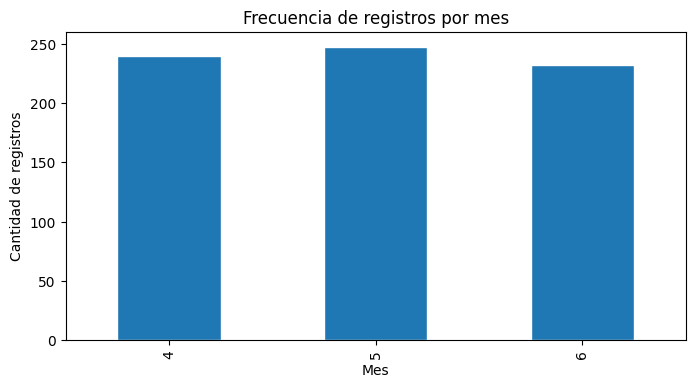

In [ ]:
#para los meses
df['mes'].value_counts().sort_index().plot.bar(
    figsize=(8, 4), edgecolor='white'
)
plt.title('Frecuencia de registros por mes')
plt.xlabel('Mes')
plt.ylabel('Cantidad de registros')
plt.show()

Mayo tiene la mayor cantidad de registros, mientras que junio tiene la menor. Sin embargo, las diferencias son pequeñas y no existe un mes claramente dominante.

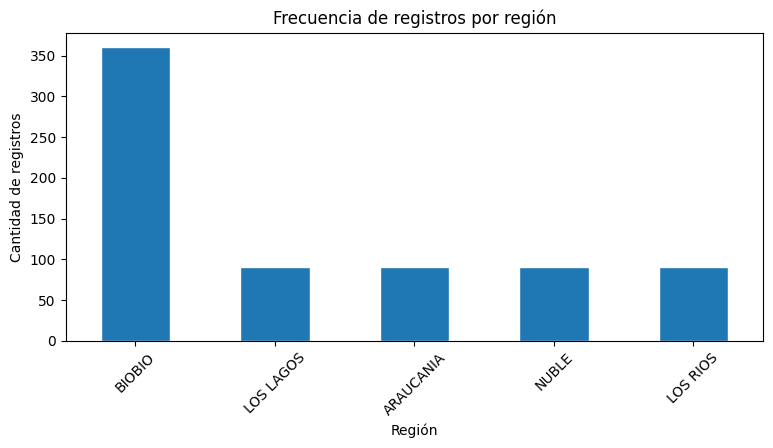

In [ ]:

#Para las regiones
import matplotlib.pyplot as plt
df['region'].value_counts().plot.bar(
    figsize=(9, 4), edgecolor='white'
)
plt.title('Frecuencia de registros por región')
plt.xlabel('Región')
plt.ylabel('Cantidad de registros')
plt.xticks(rotation=45)
plt.show()

Aquí aparece una diferencia importante:
- Biobío representa el 50% del conjunto, con 360 registros.
- Cada una de las otras cuatro regiones representa el 12,5%, con 90 registros.
Esto ocurre porque Biobío agrupa cuatro estaciones y las demás regiones solamente una cada una.

Por lo tanto, las comparaciones regionales deben interpretarse con precaución, ya que la cantidad de estaciones no es igual entre regiones.

Resumen:\
No se identifican categorías con una cantidad tan baja de registros que justifique agruparlas.
- Estaciones: las 8 estaciones tienen 90 registros cada una (12,5%).
- Meses: abril tiene 240 registros (33,33%), mayo 248 (34,44%) y junio 232 (32,22%).
- Regiones: Biobío tiene 360 registros (50%), mientras que Los Lagos, Araucanía, Ñuble y Los Ríos tienen 90 registros cada una (12,5%).\

Si existe una categoría que domina el conjunto y que podría sesgar las conclusiones y esta es la Región del BioBío que concentra el 50% de los registros.
Esto ocurre porque incluye cuatro estaciones de monitoreo, mientras que las demás regiones tienen solamente una.

Por lo tanto, si calculamos un promedio general de PM2.5 utilizando todos los registros, las estaciones del Biobío tendrán mayor peso en el resultado.

Sin embargo, esto no significa necesariamente que exista un sesgo estadístico. Dependerá de qué población o territorio se quiera representar con el análisis.

---
## Parte 2 · Análisis bivariado y agrupación

Ahora las relaciones. Aquí es donde empiezan a aparecer los hallazgos, y también los espejismos.

### ✏️ Actividad 2.1 — Comportamiento por grupo

Agrupa por tu variable categórica más importante y compara una métrica numérica entre grupos. Usa `groupby` con al menos tres estadísticos (`count`, `median`, `std`).

**Incluye siempre el `count`.** Una diferencia espectacular entre grupos deja de serlo cuando uno de ellos tiene cuatro casos.

+++++++\
Comenzamos a relacionar dos variables:
- Variable categórica: estacion, que identifica las ocho estaciones de monitoreo.
- Variable numérica: pm25, que representa la concentración de material particulado fino.\

El objetivo es determinar si las concentraciones de PM2.5 son diferentes entre las estaciones.

In [ ]:
# Tu código aquí
tabla = df.groupby('estacion')['pm25'].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

display(tabla)

,count,mean,median,std
estacion,,,,
CORONEL NORTE,88,47.43,49.50,10.44
COYHANCO,87,72.55,67.00,46.96
KINGSTON,90,50.98,43.40,47.87
LOS ANGELES ORIENTE,82,78.56,62.05,86.09
OSORNO ENTRE LAGOS,87,67.20,59.10,54.08
TALCAHUANO,87,43.90,40.40,32.83
TEMUCO PADRE LAS CASAS,82,81.11,74.75,52.80
VALDIVIA CENTRO,83,58.78,57.70,34.81


_Tu lectura:_\
La frase «Una diferencia espectacular entre grupos deja de serlo cuando uno de ellos tiene cuatro casos» significa que una diferencia muy grande entre los resultados de dos grupos puede ser poco confiable si uno de ellos tiene muy pocas observaciones.

Los resultados muestran que existen diferencias importantes en las concentraciones de PM2.5 entre las ocho estaciones, tanto en sus valores centrales como en su variabilidad.\
**Comparación de medianas:**\
Las estaciones con mayores medianas son:
- Temuco Padre Las Casas: 74,75 µg/m³.
- Coyhanco: 67,00 µg/m³.
- Los Ángeles Oriente: 62,05 µg/m³.
La menor mediana corresponde a Talcahuano, con 40,40 µg/m³.

Esto significa que la concentración típica de PM2.5 en Temuco Padre Las Casas es aproximadamente 1,85 veces la de Talcahuano.

**Comparación de la variabilidad (std):**\
La desviación estándar permite identificar las estaciones donde las concentraciones fluctúan más.
Los Ángeles Oriente presenta la mayor variabilidad. Su desviación estándar de 86,09 es incluso superior a su promedio de 78,56, lo que sugiere la presencia de concentraciones muy elevadas o una dispersión considerable.

En cambio, Coronel Norte presenta la menor variabilidad, con una desviación estándar de 10,44, indicando mediciones más concentradas alrededor de su promedio.

**Comparación en la cantidad de registros**\
Todas las estaciones tienen entre 82 y 90 mediciones válidas. Por lo tanto, ninguna presenta un tamaño de grupo extremadamente pequeño.

Sin embargo, los valores faltantes podrían influir en las comparaciones si no se distribuyen aleatoriamente.

**Diferencias entre media y mediana**\
Un resultado interesante es el de Kingston:
- Media: 50,98 µg/m³.
- Mediana: 43,40 µg/m³.
- Desviación estándar: 47,87 µg/m³.
La diferencia entre media y mediana, junto con la alta dispersión, sugiere que algunas mediciones elevadas podrían estar aumentando el promedio.

En Temuco Padre Las Casas, la media de 81,11 también supera la mediana de 74,75.

Estas diferencias refuerzan la conveniencia de utilizar la mediana para describir la concentración típica.



### ✏️ Actividad 2.2 — Matriz de correlación

Calcula y grafica la matriz de correlación de tus variables numéricas. Identifica los dos pares con mayor correlación.

+++++\
El objetivo es determinar qué variables numéricas están relacionadas entre sí y qué tan fuerte es esa relación.

En este conjunto de datos de calidad del aire podemos estudiar las relaciones entre PM2.5, PM10, temperatura y humedad.

Se deben revisar los coeficientes de correlación de Pearson (r)

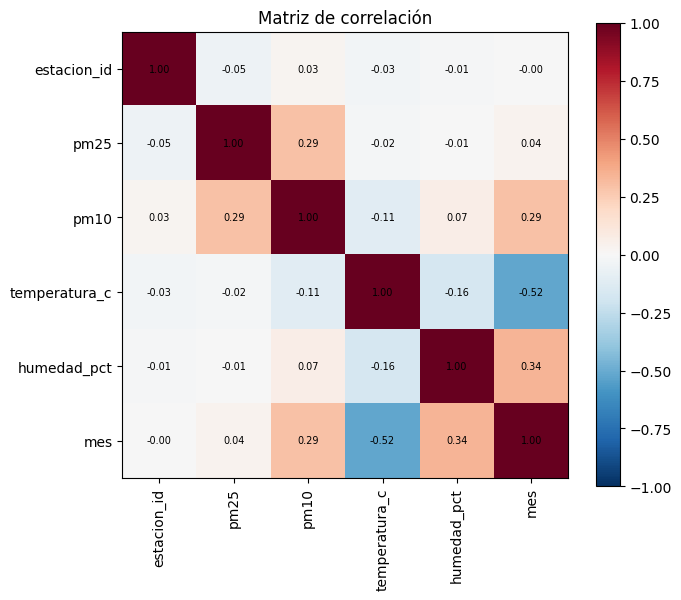

In [ ]:
corr = df.select_dtypes(include='number').corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); plt.title('Matriz de correlación'); plt.tight_layout(); plt.show()

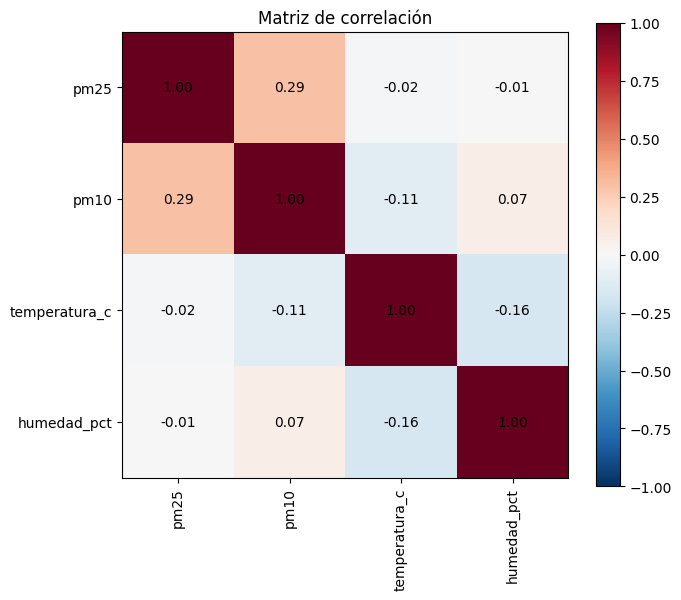

In [ ]:
import matplotlib.pyplot as plt

# ------ Acá se seleccionan sólo variables numéricas relevantes
variables = ['pm25', 'pm10', 'temperatura_c', 'humedad_pct']

# Calcular matriz de correlación
corr = df[variables].corr()

# Graficar
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)

ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)

ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)

for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}',
                ha='center', va='center', fontsize=10)

plt.colorbar(im)
plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()

++++++++\
La matriz muestra que las relaciones lineales entre las variables son débiles. Ningún par presenta una correlación fuerte.

Primer par: PM2.5 y PM10 (r = 0,29)

Existe una relación positiva débil. Esto significa que cuando aumenta PM10, PM2.5 también tiende a aumentar, pero la relación no es muy marcada.

Segundo par: temperatura y humedad (r = -0,16)

Existe una relación negativa débil. Esto significa que cuando aumenta la temperatura, la humedad relativa tiende a disminuir ligeramente.

Un hallazgo interesante es que PM2.5 prácticamente no presenta relación lineal con la temperatura ni con la humedad en el conjunto analizado.

Esto no significa que las condiciones meteorológicas no influyan en la contaminación, sino que no se observa una relación lineal clara en estos datos.

¿Por qué PM2.5 y PM10 tienen una correlación relativamente baja?
Aunque ambas variables representan material particulado, pueden presentar comportamientos diferentes.

Algunas explicaciones posibles son:
- Las partículas pueden provenir de distintas fuentes de emisión.
- Las condiciones meteorológicas pueden afectar de manera diferente a cada tipo de partícula.
- Los valores extremos de PM2.5 podrían influir en el coeficiente de Pearson.
- Al combinar estaciones y meses, podrían ocultarse relaciones que existen dentro de grupos específicos.
Estas son hipótesis que necesitarían análisis adicionales.

### ✏️ Actividad 2.3 — El par más correlacionado, bajo sospecha

Toma el par con mayor correlación y **no te quedes con el número**. Haz el recorrido del Ejercicio 4:

1. Grafica el diagrama de dispersión. ¿La relación es lineal, o el coeficiente engaña?
2. ¿Alguna de las dos variables depende del **tamaño** de la unidad de análisis? Si es así, **normalízalas** y vuelve a calcular.
3. Piensa qué **tercera variable** podría estar causando ambas, y calcula la correlación parcial.
4. Si tienes una variable de agrupación, repite el cálculo **dentro de un solo grupo**.

++++++\
En esta actividad debemos investigar si la correlación encontrada entre dos variables es realmente representativa o si está influida por otros factores.

En tu matriz anterior, el par con mayor correlación fue:

PM2.5 y PM10, con r = 0,29 (correlación positiva débil).

Vamos a desarrollar los cuatro pasos utilizando este conjunto de datos.

1) Graficar el diagrama de dispersión:

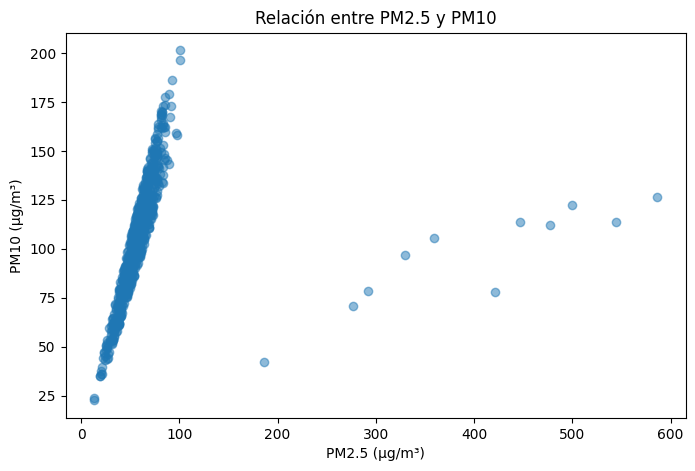

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(df['pm25'], df['pm10'], alpha=0.5)

plt.title('Relación entre PM2.5 y PM10')
plt.xlabel('PM2.5 (µg/m³)')
plt.ylabel('PM10 (µg/m³)')
plt.show()

Este gráfico revela algo muy importante: la relación entre PM2.5 y PM10 parece ser mucho más fuerte para la mayoría de los registros de lo que sugiere la correlación general de r = 0,29.

En el gráfico se distinguen dos comportamientos:

Grupo principal de mediciones:
- La mayoría de los puntos se concentra entre aproximadamente 0 y 100 µg/m³ de PM2.5.
- Los puntos forman una franja ascendente muy estrecha.
- Esto sugiere una relación lineal positiva fuerte dentro de ese conjunto de observaciones.\

Valores extremos:
- Aparecen algunos puntos con PM2.5 entre aproximadamente 190 y 590 µg/m³.
- Estos puntos se encuentran alejados de la concentración principal.
- No siguen la misma tendencia lineal que el resto de las mediciones.

¿Por qué Pearson entrega solamente r = 0,29?\
Porque los valores extremos pueden alterar considerablemente el coeficiente de correlación de Pearson.

En este gráfico, la mayoría de los puntos sigue una tendencia ascendente muy clara, pero unas pocas observaciones alejadas presentan un comportamiento diferente.

Estas observaciones pueden reducir la correlación global, aunque exista una relación lineal fuerte en el grupo principal.

Esto explica por qué no debemos interpretar una correlación utilizando solamente el valor de r.

2) ¿PM2.5 y PM10 dependen del tamaño de la unidad de análisis?\
No, en este conjunto de datos, ninguna de las dos variables depende directamente del tamaño de la unidad de análisis.

Esto se debe a que:
- PM2.5: representa la concentración de partículas finas en el aire, medida en µg/m³.
- PM10: representa la concentración de partículas de mayor tamaño, también medida en µg/m³.
- Unidad de análisis: cada registro corresponde a una medición de calidad del aire en una estación y fecha determinadas.
Ambas variables ya están expresadas como concentraciones por unidad de volumen de aire.

Por lo tanto, no es necesario normalizarlas por tamaño para calcular su correlación.

3) Piensa qué tercera variable podría estar causando ambas, y calcula la correlación parcial.\
En este conjunto de datos hay dos candidatas:
- temperatura_c: las condiciones térmicas pueden relacionarse con la dispersión y acumulación de contaminantes.
- humedad_pct: la humedad puede afectar el comportamiento de las partículas y, dependiendo de los instrumentos, sus mediciones.\

Para comenzar utilizaremos temperatura, aunque no podemos afirmar que sea la causa de ambas concentraciones.

In [ ]:
def correlacion_parcial(x, y, z):
    """Correlación entre x e y una vez removido el efecto lineal de z."""
    res_x = x - np.polyval(np.polyfit(z, x, 1), z)
    res_y = y - np.polyval(np.polyfit(z, y, 1), z)
    return np.corrcoef(res_x, res_y)[0, 1]

# Tu código aquí
datos = df[['pm25', 'pm10', 'temperatura_c']].dropna()

# Correlación original
r_original = datos['pm25'].corr(datos['pm10'])

# Correlación parcial controlando temperatura
r_parcial = correlacion_parcial(
    datos['pm25'],
    datos['pm10'],
    datos['temperatura_c']
)

print('Correlación original:', round(r_original, 2))
print('Correlación parcial:', round(r_parcial, 2))

Correlación original: 0.29
Correlación parcial: 0.29


+++++\
La correlación entre PM2.5 y PM10 prácticamente no cambia al controlar la temperatura.\
Esto indica que:
- La relación entre PM2.5 y PM10 sigue siendo positiva y débil.
- La temperatura no parece explicar una parte importante de la asociación lineal entre ambas variables.
- La correlación observada no depende de manera apreciable del efecto lineal de la temperatura.


++++\
Ahora utilizaremos humedad_pct como tercera variable para determinar si la humedad influye en la relación entre PM2.5 y PM10.

In [ ]:
datos = df[['pm25', 'pm10', 'humedad_pct']].dropna()

# Correlación original
r_original = datos['pm25'].corr(datos['pm10'])

# Correlación parcial controlando humedad
r_parcial = correlacion_parcial(
    datos['pm25'],
    datos['pm10'],
    datos['humedad_pct']
)

print('Correlación original:', round(r_original, 2))
print('Correlación parcial:', round(r_parcial, 2))

Correlación original: 0.29
Correlación parcial: 0.29


La correlación entre PM2.5 y PM10 prácticamente no cambia al controlar la humedad relativa.

Esto indica que:
- La relación entre PM2.5 y PM10 continúa siendo positiva y débil.
- La humedad no parece explicar una parte importante de la asociación lineal entre ambas variables.
- Tanto la temperatura como la humedad producen cambios muy pequeños o nulos en la correlación observada.

_Tu conclusión sobre ese par. ¿Hay relación real, o hay un confundidor? ¿Cuál?_

Entre PM2.5 y PM10 existe una correlación positiva débil (r = 0,29). Sin embargo, el diagrama de dispersión muestra una relación lineal más marcada en la mayoría de las mediciones, junto con algunos valores extremos que podrían estar afectando el resultado.

Al controlar la temperatura y la humedad mediante correlaciones parciales, el coeficiente se mantiene en 0,29. Esto indica que ninguna de estas variables parece actuar como un confundidor importante de la relación lineal observada.

Por lo tanto, existe una asociación entre PM2.5 y PM10, pero todavía no es posible determinar completamente su intensidad ni descartar otros factores. Los valores extremos y las diferencias entre estaciones podrían estar influyendo en la correlación general.

---
## Parte 3 · Series temporales

**Si tu conjunto tiene una variable de fecha, esta parte es obligatoria.** Si no la tiene, reemplázala por un análisis bivariado adicional y dilo explícitamente aquí.

### ✏️ Actividad 3.1 — Construir la serie

Agrega tu conjunto por período (mes, semana o día, según corresponda) y grafica la evolución de tu métrica principal.

En este conjunto de datos de calidad del aire tenemos una columna fecha y mediciones de PM2.5, por lo que podemos construir una serie temporal para analizar cómo evoluciona la contaminación entre abril y junio de 2026.

Como tu pregunta analítica busca estudiar el comportamiento de PM2.5, utilizaremos esta variable como métrica principal.

In [ ]:
# Tu código aquí. Sugerencia:
# df['fecha'] = pd.to_datetime(df['TU_COLUMNA_FECHA'])
# serie = df.set_index('fecha')['TU_METRICA'].resample('MS').sum()
# serie.plot(title='Evolución mensual'); plt.show()


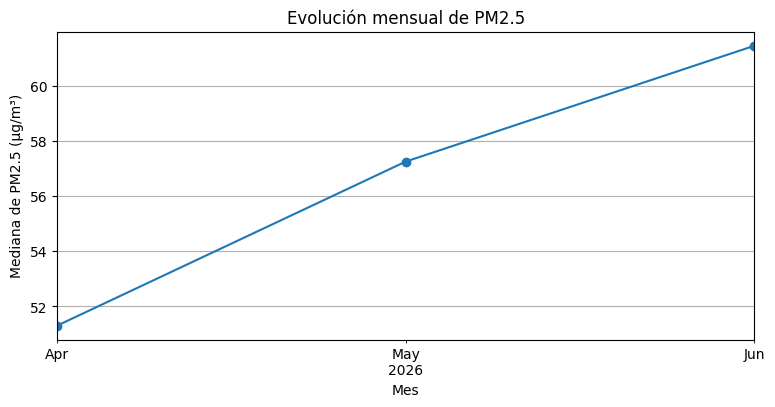

fecha
2026-04-01    51.30
2026-05-01    57.25
2026-06-01    61.45
Freq: MS, Name: pm25, dtype: float64


mes,4,5,6
estacion,,,
CORONEL NORTE,40.70,48.15,57.05
COYHANCO,61.40,66.65,73.60
KINGSTON,39.45,40.50,53.40
LOS ANGELES ORIENTE,55.00,63.10,69.10
OSORNO ENTRE LAGOS,55.15,59.20,67.10
TALCAHUANO,32.55,39.65,45.50
TEMUCO PADRE LAS CASAS,70.40,74.70,81.50
VALDIVIA CENTRO,48.10,55.45,60.85


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Convertir la columna fecha a datetime
df['fecha'] = pd.to_datetime(df['fecha'])

# Agrupar por mes y calcular la mediana de PM2.5
serie = df.set_index('fecha')['pm25'].resample('MS').median()

# Graficar
serie.plot(figsize=(9, 4), marker='o')

plt.title('Evolución mensual de PM2.5')
plt.xlabel('Mes')
plt.ylabel('Mediana de PM2.5 (µg/m³)')
plt.grid(True)
plt.show()

print(serie.round(2)) #Valores exactos
#agrupado por estacion
tabla_mensual = df.groupby(
    ['estacion', 'mes']
)['pm25'].median().unstack()
display(tabla_mensual.round(2))

El gráfico muestra una tendencia creciente en la mediana mensual de PM2.5 entre abril y junio de 2026.

Se identifican tres características importantes:
- Tendencia creciente: la mediana aumenta durante los tres meses.
- Incremento sostenido: no se observan disminuciones entre los meses analizados.
- Mayor concentración en junio: junio presenta la mediana más elevada, mientras que abril registra la menor.\
La diferencia entre abril y junio es aproximadamente 10,1 µg/m³, equivalente a un aumento cercano al 20%.

Lo qué podría explicar este comportamiento es que en Chile, abril, mayo y junio corresponden al otoño y al comienzo del invierno.

El aumento de PM2.5 podría estar relacionado con factores como el uso de calefacción residencial, las condiciones de ventilación atmosférica o la acumulación de contaminantes.

Sin embargo, estas son posibles explicaciones y no podemos atribuir el aumento a una causa específica solamente con este gráfico.

Además, la serie reúne ocho estaciones de diferentes ciudades, y se ve que el incremento ocurre en todas ellas.

### ✏️ Actividad 3.2 — Descomposición

Si tu serie tiene al menos **dos ciclos completos** (por ejemplo, 24 meses), descompónla en tendencia, estacionalidad y residuo.

Después responde: ¿qué muestra el **residuo**? ¿Hay algún período anómalo?

+++++\
Esta actividad busca separar una serie temporal en tres componentes:
1. Tendencia: comportamiento general de los datos a lo largo del tiempo, ya sea creciente, decreciente o estable.
2. Estacionalidad: patrones que se repiten periódicamente, por ejemplo, aumentos de contaminación durante ciertos meses del año.
3. Residuo: variaciones que no son explicadas por la tendencia ni por la estacionalidad. Puede contener fluctuaciones aleatorias y anomalías.

Este conjunto de datos contiene mediciones de PM2.5 sólo correspondientes a abril, mayo y junio de 2026. Si utilizamos una serie mensual, solamente tendremos 3 observaciones, mientras que el ejercicio solicita al menos dos ciclos completos (24 meses). Otra opción de periodicidad es Semenal (ciclo de 7 días)

Por lo tanto, no podemos descomponer adecuadamente una serie mensual con estacionalidad anual, porque solamente tenemos tres meses.

Sin embargo, podemos explorar una posible estacionalidad semanal utilizando las mediciones diarias.

Días sin datos: 0


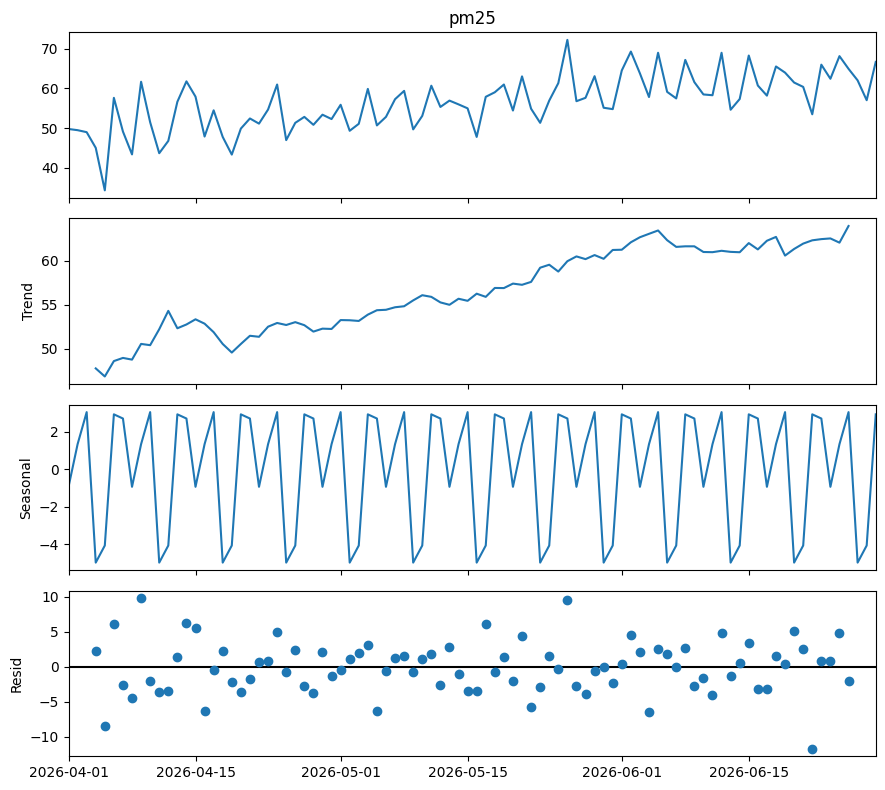

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Construir serie diaria
serie_diaria = df.set_index('fecha')['pm25'].resample('D').median()

# Revisar valores faltantes
print('Días sin datos:', serie_diaria.isna().sum())

# Descomposición semanal
desc = seasonal_decompose(
    serie_diaria.dropna(),
    model='additive',
    period=7
)

# Graficar
fig = desc.plot()
fig.set_size_inches(9, 8)

plt.tight_layout()
plt.show()

In [ ]:
# from statsmodels.tsa.seasonal import seasonal_decompose
# desc = seasonal_decompose(serie, model='additive', period=12)
# fig = desc.plot(); fig.set_size_inches(9, 8); plt.tight_layout(); plt.show()

# Tu código aquí


_Tu lectura de la tendencia, la estacionalidad y el residuo:_



Se distinguen cuatro componentes:

1. Serie original\
El primer gráfico muestra las concentraciones diarias de PM2.5.
- Las concentraciones fluctúan aproximadamente entre 40 y 70 µg/m³.
- Se observa un aumento general desde abril hacia junio.
- Existen días con concentraciones más elevadas, especialmente durante la segunda mitad del período.
Interpretación: la concentración típica diaria de PM2.5 tiende a aumentar durante los tres meses analizados.
2. Tendencia \
El segundo gráfico muestra una tendencia claramente creciente.
- A comienzos de abril, la tendencia se sitúa alrededor de 48 µg/m³.
- Durante mayo aumenta progresivamente.
- En junio alcanza valores cercanos a 65 µg/m³.
Esto indica que las concentraciones de PM2.5 aumentan de manera sostenida en el período estudiado, aunque existen pequeñas fluctuaciones.

Una posible explicación es el cambio estacional hacia los meses más fríos, pero el gráfico no permite demostrar esa causa.

3. Estacionalidad \
El tercer gráfico muestra un patrón semanal estimado que se repite cada siete días.
- Las variaciones estacionales oscilan aproximadamente entre -4 y +3 µg/m³.
- Se observa una repetición regular de aumentos y disminuciones.
- La magnitud de estas variaciones es menor que el incremento observado en la tendencia.
Importante: el método fue configurado con period=7, por lo que el algoritmo estima y repite un componente semanal. Esto no demuestra por sí solo que exista una estacionalidad semanal real.

Para confirmarla, sería conveniente comparar las concentraciones por día de la semana.

4. Residuo \
El cuarto gráfico muestra las variaciones que no son explicadas por la tendencia ni por el componente semanal estimado.

Se observa que:
- La mayoría de los residuos se encuentra aproximadamente entre -5 y +5 µg/m³.
- Existen algunos residuos positivos cercanos a +10 µg/m³.
- También aparece un residuo negativo cercano a -12 µg/m³ hacia finales de junio.
Estos valores podrían corresponder a días con concentraciones inusuales respecto del comportamiento esperado por la descomposición.

Sin embargo, un residuo elevado no significa necesariamente un error en los datos. Podría reflejar un episodio real de contaminación o condiciones ambientales particulares.

### ✏️ Actividad 3.3 — La comparación honesta

Si tu serie tiene estacionalidad, calcula la variación entre dos períodos consecutivos y la variación interanual del mismo período. Muestra la diferencia entre ambas lecturas (Ejercicio 6).

++++\
Esta actividad busca demostrar que comparar dos períodos consecutivos no es lo mismo que comparar el mismo período de años diferentes, especialmente cuando existe estacionalidad.

En tu conjunto de datos tenemos mediciones de PM2.5 entre abril y junio de 2026.

Comparación--Ejemplo--¿Qué permite observar?\
Variación entre períodos consecutivos--Mayo 2026 frente a abril 202--Cambio de un mes al siguiente\
Variación interanual--Mayo 2026 frente a mayo 2026--Cambio respecto del mismo mes del año anterior.

La comparación interanual es útil porque permite reducir el efecto de patrones estacionales que se repiten cada año.

In [ ]:
# Tu código aquí
#Código para calcular la variación mensual
import pandas as pd

# Asegurar formato de fecha
df['fecha'] = pd.to_datetime(df['fecha'])

# Construir serie mensual
serie = df.set_index('fecha')['pm25'].resample('MS').median()

# Variación mensual porcentual
variacion_mensual = serie.pct_change() * 100

# Variación interanual porcentual
variacion_interanual = serie.pct_change(periods=12, fill_method=None) * 100

# Tabla de resultados
tabla = pd.DataFrame({
    'Mediana PM2.5': serie,
    'Variación mensual (%)': variacion_mensual,
    'Variación interanual (%)': variacion_interanual
})

display(tabla.round(2))

,Mediana PM2.5,Variación mensual (%),Variación interanual (%)
fecha,,,
2026-04-01,51.30,NaN,NaN
2026-05-01,57.25,11.60,NaN
2026-06-01,61.45,7.34,NaN


Interpretación de la Actividad 3.3 — La comparación honesta\
Los resultados muestran que la mediana de PM2.5 aumentó durante los tres meses analizados, aunque el incremento porcentual fue menor entre mayo y junio.
Esto significa que las concentraciones típicas continuaron aumentando, pero a un ritmo porcentual menor.

NaN significa que no existe un valor disponible para realizar el cálculo.
Como este conjunto contiene solamente abril, mayo y junio de 2026, no es posible comparar esos meses con los correspondientes de 2025.\
Por lo tanto, no podemos determinar si el aumento observado corresponde a un patrón estacional habitual o a un incremento excepcional.

La comparación mensual muestra que la contaminación aumentó durante el período estudiado.

Sin embargo, una comparación interanual permitiría evaluar si las concentraciones son mayores o menores que las registradas en los mismos meses del año anterior, reduciendo así la influencia de la estacionalidad anual.

---
## Parte 4 · Hipótesis de trabajo

Esto es lo que la semana 4 va a poner a prueba. Una hipótesis de trabajo no es una corazonada: es una afirmación **falsable** que surge de la evidencia que acabas de producir.

### ✏️ Actividad 4.1 — Formula dos hipótesis

Cada una debe indicar:

- **La afirmación**, en una frase.
- **La evidencia exploratoria** que la sugiere (qué gráfico, qué número, en qué celda).
- **Qué la refutaría**: qué tendrías que observar para descartarla.
- **Qué confundidor podría explicarla** sin que la relación sea real.

Si no puedes escribir qué la refutaría, no es una hipótesis: es una opinión.

A partir de los análisis exploratorios realizados sobre este conjunto de datos de calidad del aire, podemos formular dos hipótesis que sean medibles, comprobables y falsables.

Se propone una hipótesis relacionada con las diferencias entre estaciones y otra con la evolución temporal de PM2.5.:\
**Hipótesis 1 — Diferencias de contaminación entre estaciones**\
Afirmación: La concentración típica de PM2.5 en la estación Temuco Padre Las Casas es mayor que en la estación Talcahuano durante el período abril-junio de 2026.

Evidencia exploratoria: En la Actividad 2.1, el análisis mediante groupby() mostró que Temuco Padre Las Casas tiene una mediana de 74,75 µg/m³, mientras que Talcahuano presenta una mediana de 40,40 µg/m³. Ambas estaciones cuentan con una cantidad similar de mediciones válidas (82 y 87, respectivamente).

Qué la refutaría: Que un análisis estadístico posterior no encuentre evidencia suficiente de que la mediana de PM2.5 en Temuco Padre Las Casas sea mayor que en Talcahuano, o que la diferencia desaparezca al controlar factores relevantes.

Confundidor posible: Las condiciones meteorológicas, como la temperatura, la humedad o la ventilación atmosférica, podrían influir en las concentraciones de PM2.5 y explicar parte de las diferencias entre estaciones.

**Hipótesis 2 — Aumento temporal de PM2.5**\
Afirmación: La concentración típica de PM2.5 aumenta entre abril y junio de 2026 en las estaciones de monitoreo analizadas.

Evidencia exploratoria: En la Actividad 3.3, la mediana mensual de PM2.5 aumentó desde 51,30 µg/m³ en abril hasta 57,25 µg/m³ en mayo y 61,45 µg/m³ en junio. Las variaciones mensuales fueron positivas: 11,60% y 7,34%, respectivamente. La tendencia creciente también se observó en la descomposición temporal de la Actividad 3.2.

Qué la refutaría: Que al analizar las estaciones individualmente no se observe un incremento consistente de PM2.5 entre abril y junio, o que el aumento general desaparezca al controlar las diferencias de composición y disponibilidad de mediciones entre estaciones.

Confundidor posible: El descenso estacional de las temperaturas y los cambios asociados en el uso de calefacción podrían explicar parte del incremento observado, sin que exista una tendencia creciente independiente de las condiciones estacionales.

---
## Parte 5 · Cierre y versionado

In [ ]:
# Guarda el conjunto con las variables derivadas que hayas creado esta semana
df.to_csv(RUTA + 'mi_conjunto_explorado.csv', sep=';', index=False)
print('Guardado:', df.shape)

Guardado: (720, 12)


In [ ]:
# En una terminal:
# git add S3_Notebook_Laboratorio_CDD.ipynb mi_conjunto_explorado.csv
# git commit -m 'Semana 3: analisis exploratorio y series temporales'
# git push


**Enlace a mi repositorio:** _…_

---

## Antes de entregar

- [ ] Al menos tres distribuciones graficadas y **leídas**, no solo mostradas
- [ ] Media contra mediana decidida y justificada
- [ ] Comparación por grupos con el `count` incluido
- [ ] Matriz de correlación calculada e interpretada
- [ ] El par más correlacionado sometido al recorrido de confundidores
- [ ] Serie temporal descompuesta, con lectura del residuo (o justificación de por qué no aplica)
- [ ] Dos hipótesis de trabajo, cada una con qué la refutaría
- [ ] Cada celda de código seguida de su celda de interpretación
- [ ] Cuaderno ejecutado de principio a fin, con las salidas visibles

Recuerda: **esta semana no hay sesión sincrónica**. Las dudas, al Foro de Consultas.

_Ciencia de Datos · Advance UCSC · Semana 3_